ESERCIZIO

Calcolo manuale e API dellla similitudine
1) Genera gli embedding per due frasi: "il gatto dorme sul divano" e "un felino riposa sul mobile"
2) Calcola la similitudine cosina tra i due vettori usando numpy
3) Confronta il risultato con la similitudine tra la prima frase e una terza frase totalmente irrilevante (es. "l'inflazione è aumentata del 2%")
4) Visualizza i tre punti in uno spazio semplificato

Suggerimento: usa la funzione dot(a,b)/norm(a)*norm(b) per la verifica matematica.

Recupero dei vettori semantici tramite API...

ANALISI MATEMATICA:
--------------------------------------
Somiglianza (Gatto vs Felino): 0.7598 (Contesto simile)
Somiglianza (Gatto vs Economia): 0.3516 (Contesto differente)


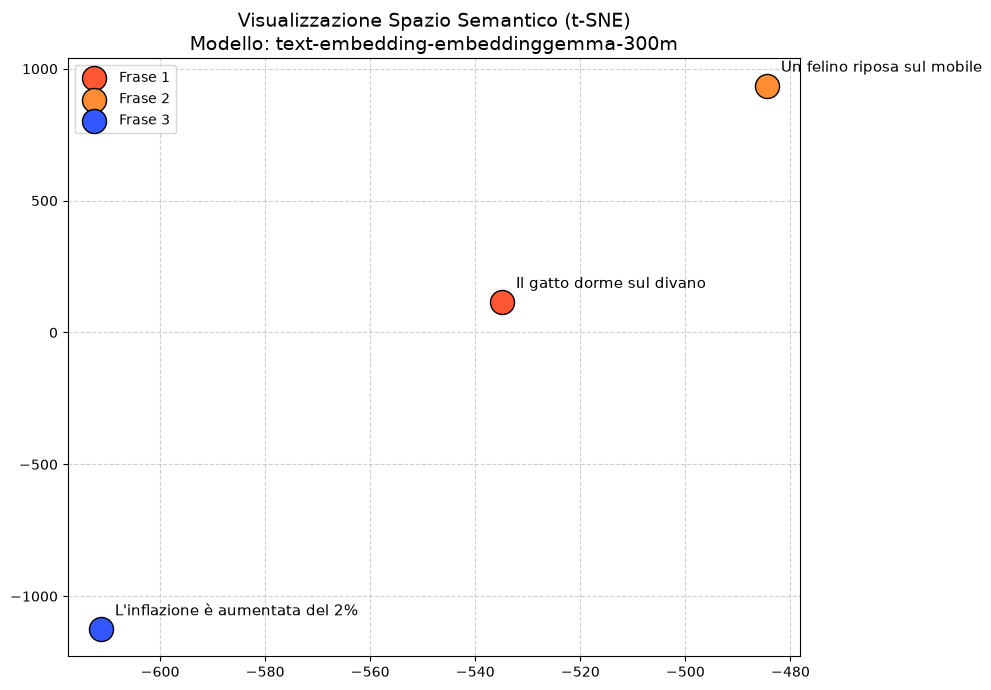

: 

In [ ]:
import torch
import requests
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from numpy.linalg import norm

# --- CONFIGURAZIONE E ESTRAZIONE DEI VETTORI (EMBEDDINGS) ---

# Indirizzo API locale per la generazione degli embeddings
URL_BASE = "http://localhost:1234/v1/embeddings"
# Nome del modello caricato nel server locale
MODEL_NAME = "text-embedding-embeddinggemma-300m"

def get_emb(text):
    """
    Invia un testo all'API locale e riceve il vettore numerico (embedding) corrispondente.
    L'embedding rappresenta il significato semantico della frase in uno spazio vettoriale.
    """
    # Predisposizione dei dati per la richiesta POST (testo di input e nome modello)
    payload = {"input": text, "model": MODEL_NAME}
    # Esecuzione della richiesta HTTP al server locale
    response = requests.post(URL_BASE, json=payload)
    # Estrazione del vettore dalla risposta JSON e conversione in array NumPy per i calcoli successivi
    return np.array(response.json()["data"][0]["embedding"])

# Definizione delle frasi da analizzare per testare la somiglianza semantica
s1 = "Il gatto dorme sul divano"        # Frase di riferimento
s2 = "Un felino riposa sul mobile"       # Frase semanticamente simile a s1
s3 = "L'inflazione è aumentata del 2%"  # Frase semanticamente distante (contesto economico)

print("Recupero dei vettori semantici tramite API...")
# Otteniamo i vettori numerici (v1, v2, v3) per ciascuna delle frasi definite sopra
v1, v2, v3 = get_emb(s1), get_emb(s2), get_emb(s3)

# --- CALCOLO DELLA SIMILARITA DEL COSENO (VETTORIZZAZIONE MANUALE) ---

def cosine_similarity(a, b):
    """
    Calcola la similarità del coseno tra due vettori.
    La formula è data dal prodotto scalare tra i vettori diviso per il prodotto delle loro norme.
    Il risultato varia tra -1 e 1, dove 1 indica che i vettori sono identici in direzione (molto simili).
    """
    # Formula matematica: (a · b) / (||a|| * ||b||)
    return np.dot(a, b) / (norm(a) * norm(b))

# Calcolo del grado di somiglianza tra le diverse coppie di frasi
sim_1_2 = cosine_similarity(v1, v2) # Somiglianza tra gatto e felino
sim_1_3 = cosine_similarity(v1, v3) # Somiglianza tra gatto e inflazione

print("\nANALISI MATEMATICA:")
print("--------------------------------------")
# Stampiamo i risultati: ci aspettiamo un valore alto per sim_1_2 e basso per sim_1_3
print(f"Somiglianza (Gatto vs Felino): {sim_1_2:.4f} (Contesto simile)")
print(f"Somiglianza (Gatto vs Economia): {sim_1_3:.4f} (Contesto differente)")

# --- VISUALIZZAZIONE GRAFICA IN 2D (t-SNE) ---

# Raggruppiamo i vettori in un'unica matrice per poter applicare tecniche di riduzione dimensionale
data = np.vstack([v1, v2, v3])

# Poiché i vettori originali hanno centinaia di dimensioni, utilizziamo t-SNE per proiettarli in 2D.
# - n_components=2: specifica che vogliamo ottenere coordinate X e Y.
# - perplexity=1: parametro regolato per il basso numero di campioni (solo 3 frasi).
# - random_state=42: garantisce che il grafico sia riproducibile ad ogni esecuzione.
tsne = TSNE(n_components=2, perplexity=1, random_state=42, init='pca', learning_rate=200)
coords = tsne.fit_transform(data)

# --- GENERAZIONE DEL GRAFICO CON MATPLOTLIB ---

# Creazione della figura con dimensioni specifiche
plt.figure(figsize=(10, 7))
# Aggiunta di una griglia di sfondo per facilitare la lettura delle distanze
plt.grid(True, linestyle='--', alpha=0.6)

# Caratterizzazioni grafiche (colori e testi)
colors = ['#FF5733', '#FF8D33', '#3357FF']
labels = [s1, s2, s3]

# Ciclo per tracciare ogni punto calcolato da t-SNE sul grafico cartesiano
for i in range(3):
    # plt.scatter disegna il punto (coordinata X, coordinata Y)
    plt.scatter(coords[i, 0], coords[i, 1], color=colors[i], s=300, edgecolors='k', label=f"Frase {i+1}")
    # plt.annotate inserisce il testo della frase accanto al punto corrispondente
    plt.annotate(labels[i], (coords[i, 0], coords[i, 1]), xytext=(10, 10), textcoords='offset points', fontsize=11)

# Impostazione del titolo, della legenda e visualizzazione finale
plt.title(f"Visualizzazione Spazio Semantico (t-SNE)\nModello: {MODEL_NAME}", fontsize=14)
plt.legend()
plt.tight_layout() # Ottimizza la disposizione degli elementi nel grafico
plt.show()